# 02 · Actuarial basics for Virginia: exposure, frequency, severity, pure premium

**Goal:** turn the raw claims and policies into the four numbers every insurance pricing model is built on, by **year** and by **county**, for Virginia.

| Measure | Plain English | Formula |
|---|---|---|
| **Exposure** (earned policy-years) | How much insurance was in force. One home insured for a full year = 1 policy-year. Insured for 3 months = 0.25. | add up, over policies, the fraction of the year each one was covered |
| **Frequency** | How *often* claims happen, per unit of exposure | paid claims ÷ exposure |
| **Severity** | How *big* a typical claim is | dollars paid ÷ paid claims |
| **Pure premium** (loss cost) | The average loss per policy-year: what you'd need to charge just to pay claims, before expenses or profit | dollars paid ÷ exposure = frequency × severity |

**A quick example.** A county had 2,000 policy-years of exposure, 10 paid claims, and \$300,000 paid.
Frequency = 10 ÷ 2,000 = 0.005 (5 claims per 1,000 policy-years). Severity = \$300,000 ÷ 10 = \$30,000 per claim. Pure premium = \$300,000 ÷ 2,000 = **\$150 per policy-year**, which is the same as 0.005 × \$30,000.

The reusable code lives in `src/actuarial.py`, so the later modelling notebooks compute these the same way.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from scipy import stats

# Paths (the notebook lives in notebooks/, so the project root is one level up)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import actuarial as act   # our own module: src/actuarial.py

FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

# --- Chart style: the same quiet look as notebook 01 ------------------------
BLUE = "#2a78d6"     # main data colour
ORANGE = "#eb6834"   # highlight colour (estimates / call-outs)
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 10, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2, "font.size": 10,
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "hatch.color": SURFACE, "hatch.linewidth": 1.2,
})

def save(fig, name):
    # Save a chart to reports/figures/ and show where it went
    path = FIG / f"02_{name}.png"
    fig.savefig(path)
    print(f"saved {path.relative_to(ROOT)}")

def thousands(x, pos=None):
    return f"{x:,.0f}"

def dollars_short(x, pos=None):
    # $500, $10K, $2.5M: short dollar labels so axis ticks don't collide
    if abs(x) >= 1e6:
        return f"${x / 1e6:,.0f}M" if x % 1e6 == 0 else f"${x / 1e6:,.1f}M"
    if abs(x) >= 1e4 or (abs(x) >= 1e3 and x % 1e3 == 0):
        return f"${x / 1e3:,.0f}K"
    if abs(x) >= 1e3:
        return f"${x / 1e3:,.1f}K"
    return f"${x:,.0f}"

def fmt_money(x):
    return f"${x:,.0f}"

# The named storm behind each big Virginia loss year (from the claims' floodEvent field)
STORMS = {2009: "Nov 2009 nor'easter", 2011: "Irene", 2012: "Sandy",
          2016: "Matthew", 2018: "Michael", 2024: "Helene"}

## 1. Load the data

* **Policies:** all 1.67 million Virginia policy terms (2009 onward). One row = one term (usually one year) for one building.
* **Claims:** Virginia claims with a date of loss in 2009 or later, so they line up with the years we have policies for.

In [2]:
pol = act.load_va_policies()
clm = act.load_va_claims(first_year=2009)
names = act.load_county_names()   # Census FIPS -> county name (src/download_data.py counties)

print(f"Policy terms:            {len(pol):,}")
print(f"Effective dates:         {pol.policyEffectiveDate.min().date()} to {pol.policyEffectiveDate.max().date()}")
print(f"VA claims, 2009+:        {len(clm):,}")
print(f"  of which paid (> $0):  {clm.is_paid.sum():,} ({clm.is_paid.mean():.1%})")
print(f"  total paid:            ${clm.total_paid.sum():,.0f}")
print(f"County names loaded:     {len(names):,}")

Policy terms:            1,668,793
Effective dates:         2009-01-01 to 2026-11-29
VA claims, 2009+:        19,315
  of which paid (> $0):  15,521 (80.4%)
  total paid:            $326,471,375
County names loaded:     3,235


## 2. Exposure, done properly: earned policy-years

### The idea
Notebook 01 counted policies by the year their term **started**. That's a rough count, not true exposure. A policy that starts on **1 December 2015** covers only one month of 2015 and eleven months of 2016, yet the simple count puts the whole policy in 2015.

**Earned exposure** splits every policy term across the calendar years it actually covered:

> For each policy and each year: earned = (days of cover inside that year) ÷ (days in that year)

**Worked example.** A one-year policy from 2 July 2015 to 2 July 2016 covers 183 days of 2015 and 183 days of 2016. It earns 183 ÷ 365 ≈ **0.50** policy-years in 2015 and 183 ÷ 366 ≈ **0.50** in 2016 (2016 was a leap year). The simple count would have given 2015 a full 1.0 and 2016 nothing.

It's called "earned" because insurers think of premium the same way: the money for a one-year policy is *earned* gradually, day by day, as the cover is provided.

### Rules and assumptions
1. **Cover starts** on `policyEffectiveDate` and **ends** on `policyTerminationDate`.
2. **Cancellations:** if `cancellationDateOfFloodPolicy` is earlier than the end date, cover stops on the cancellation date. If the cancellation is dated on or before the start date, the policy never provided cover ("cancelled flat") and earns 0. In the data, 3.8% of terms were cancelled, and 1,219 were cancelled flat.
3. **Unit = one policy term.** Each policy counts as 1, even a condo-association policy that covers many units (`policyCount` > 1). Each claim record is also one policy's claim, so counting the same way on top and bottom keeps frequency an apples-to-apples ratio. A version weighted by `policyCount` is shown below for comparison.
4. **2009 is under-counted.** The policy file only contains terms that *started* in 2009 or later. Policies that started in 2008 and were still running in 2009 are missing, so 2009's earned exposure is only about half the truth. We **estimate** 2009 by assuming the 2008 policies looked like the 2009 ones (the policy base changes slowly), which works out to roughly one policy-year per 2009 term. 2009 is kept, clearly marked as an estimate, because it holds Virginia's biggest event in the data (the November 2009 nor'easter). Headline averages use **2010–2025** only.
5. **2026 is excluded:** the year isn't over and claims only run to September 2026.

In [3]:
# Sanity check on made-up policies with known answers (see src/actuarial.py::_self_test):
#   * 2 Jul 2015 - 2 Jul 2016               -> 183/365 in 2015 and 183/366 in 2016
#   * a full calendar year                   -> 1.0
#   * cancelled halfway through              -> about 0.5
#   * cancelled before it started            -> 0
assert act._self_test()
print("toy-policy test passed")

YEARS_ALL = range(2009, 2028)                     # every year any policy touches
earned_all = act.earned_exposure(pol, YEARS_ALL)

# Reconciliation: earned exposure is just the total days of cover, sliced by year.
# So adding it up over ALL years must equal (total cover days / days per year).
start, end = act.coverage_period(pol)
total_cover_years = (end - start).dt.days.sum() / 365.25
print(f"Total earned, all years:   {earned_all.exposure.sum():,.0f} policy-years")
print(f"Total days of cover / 365.25: {total_cover_years:,.0f}")
assert abs(earned_all.exposure.sum() / total_cover_years - 1) < 0.001

toy-policy test passed


Total earned, all years:   1,624,225 policy-years
Total days of cover / 365.25: 1,624,118


In [4]:
YEARS = list(range(act.FIRST_FULL_YEAR, act.LAST_FULL_YEAR + 1))   # 2010-2025

compare = pd.DataFrame(index=pd.Index(range(2009, 2026), name="year"))
compare["earned (raw)"] = earned_all.set_index("year").exposure
compare["earned (2009 estimated)"] = compare["earned (raw)"]
compare.loc[2009, "earned (2009 estimated)"] = act.estimate_2009_exposure(pol).exposure[0]
compare["earned, x policyCount"] = act.earned_exposure(pol, compare.index, weight="policyCount").set_index("year").exposure
start_year = pol.policyEffectiveDate.dt.year
compare["count by start year"] = start_year.value_counts()
compare["notebook 01 (policyCount by start year)"] = pol.groupby(start_year).policyCount.sum()
print("Policy-years by method:")
display(compare.round(0).astype(int).style.format("{:,}"))

diff = (compare["count by start year"] / compare["earned (2009 estimated)"] - 1).loc[YEARS]
print(f"\n2010-2025: simple count vs earned differ by {diff.abs().mean():.1%} on average "
      f"(range {diff.min():+.1%} to {diff.max():+.1%})")
print(f"policyCount weighting adds {(compare['earned, x policyCount'] / compare['earned (raw)'] - 1).loc[YEARS].mean():.1%}")
print(f"Raw 2009 earned exposure is {compare.loc[2009, 'earned (raw)'] / compare.loc[2009, 'earned (2009 estimated)']:.0%} of the estimate")

Policy-years by method:


,earned (raw),earned (2009 estimated),"earned, x policyCount",count by start year,notebook 01 (policyCount by start year)
year,,,,,
2009,"44,431","95,990","49,915","97,993","110,453"
2010,"97,308","97,308","109,623","100,419","112,642"
2011,"99,041","99,041","111,259","103,433","115,910"
2012,"101,788","101,788","114,150","104,995","117,540"
2013,"103,184","103,184","115,838","104,331","117,091"
2014,"100,509","100,509","113,310","102,810","115,900"
2015,"96,867","96,867","109,697","97,348","110,255"
2016,"92,510","92,510","105,109","95,833","108,333"
2017,"92,082","92,082","104,474","96,791","109,170"



2010-2025: simple count vs earned differ by 2.1% on average (range +0.1% to +5.1%)
policyCount weighting adds 13.3%
Raw 2009 earned exposure is 46% of the estimate


saved reports\figures\02_exposure_methods.png


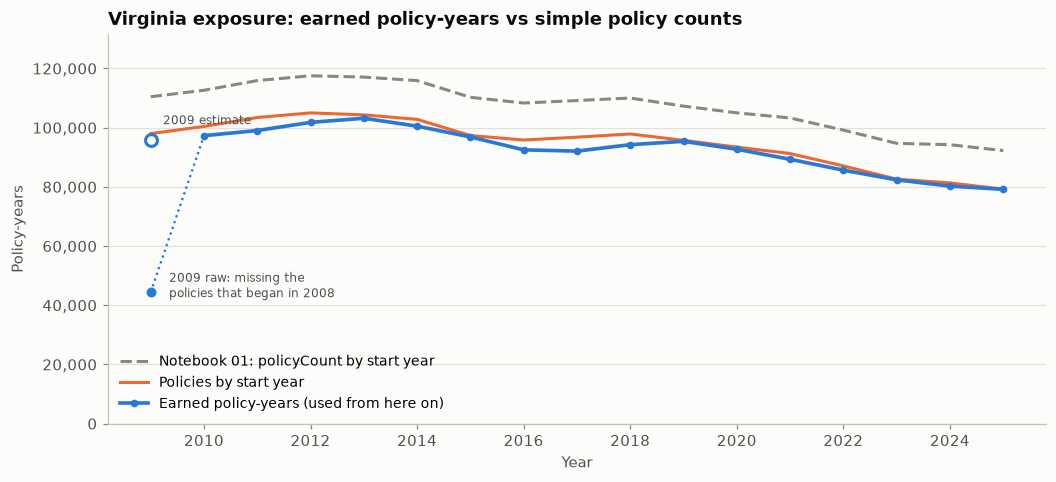

In [5]:
fig, ax = plt.subplots(figsize=(11, 4.6))
x = compare.index
ax.plot(x, compare["notebook 01 (policyCount by start year)"], color=MUTED, lw=2, ls="--",
        label="Notebook 01: policyCount by start year")
ax.plot(x, compare["count by start year"], color=ORANGE, lw=2, label="Policies by start year")
ax.plot(x[1:], compare["earned (raw)"].iloc[1:], color=BLUE, lw=2.4, marker="o", ms=4,
        label="Earned policy-years (used from here on)")
ax.plot([2009, 2010], compare["earned (raw)"].iloc[:2], color=BLUE, lw=1.5, ls=":")
ax.scatter([2009], [compare.loc[2009, "earned (raw)"]], color=BLUE, s=30, zorder=3)
ax.scatter([2009], [compare.loc[2009, "earned (2009 estimated)"]], facecolor=SURFACE,
           edgecolor=BLUE, s=60, lw=2, zorder=3)
ax.annotate("2009 raw: missing the\npolicies that began in 2008", (2009, compare.loc[2009, "earned (raw)"]),
            xytext=(12, 4), textcoords="offset points", fontsize=8, color=INK_2, va="center")
ax.annotate("2009 estimate", (2009, compare.loc[2009, "earned (2009 estimated)"]), xytext=(8, 10),
            textcoords="offset points", fontsize=8, color=INK_2)
ax.set_ylim(0, compare.max().max() * 1.12)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(thousands))
ax.xaxis.set_major_locator(mticker.MultipleLocator(2))
ax.set_ylabel("Policy-years")
ax.set_xlabel("Year")
ax.set_title("Virginia exposure: earned policy-years vs simple policy counts")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, loc="lower left", fontsize=9)
save(fig, "exposure_methods")
plt.show()

**What this shows.**
* From 2010 on, the simple count and earned exposure tell nearly the same story, because most policies renew every year: one policy ends and the next term starts, so "terms started this year" is a decent stand-in for "years of cover this year." Earned exposure is still the right measure, because it handles cancellations, multi-year terms, and a growing or shrinking policy base correctly.
* **2009 is the big exception.** Counting by start year looks fine there, but the true earned exposure for 2009 is about half of it, because the policies that were already running when 2009 began aren't in the file. Without the estimate, 2009's claim frequency would look roughly twice as high as it really was.
* Weighting by `policyCount` (counting each condo unit) adds about 10–15%. We don't weight, so that each claim record is matched to one policy.

## 3. Which payment fields? "Total paid"

Each claim has three **amount paid** fields:

| Field | What it pays for |
|---|---|
| `amountPaidOnBuildingClaim` | damage to the building |
| `amountPaidOnContentsClaim` | belongings inside |
| `amountPaidOnIncreasedCostOfComplianceClaim` | **ICC**: up to $30,000 to elevate, flood-proof, or demolish a badly damaged building to meet local building rules |

**Total paid = building + contents + ICC.** Why this choice:
* It is the full cost the insurer actually paid for the claim, which is what a premium must cover. ICC is a real cost of the policy too: it's part of the coverage, and it has its own premium charge.
* It's **paid**, not **damage**. `buildingDamageAmount` is the adjuster's damage estimate, before the deductible and coverage limits. Pricing has to be based on what the policy pays out.
* A blank payment means nothing was paid, so it counts as $0. (18% of Virginia claims since 2009 have all three fields blank. These are claims closed without payment.)
* **Cross-check:** FEMA also publishes `net...PaymentAmount` fields: payments after money recovered later (for example from a third party). For Virginia since 2009 the two totals differ by only about 0.1%, so the choice barely matters here.

**What counts as a claim?** Here a claim means a **paid claim** (total paid > $0). Closed-without-payment claims cost the insurer adjusting expense but no loss dollars. Using paid claims on both the frequency and severity side keeps the identity *pure premium = frequency × severity* exact. The "all claims" frequency is shown alongside for reference.

In [6]:
gross = clm.total_paid.sum()
net = clm[act.NET_COLS].fillna(0).sum(axis=1).sum()
print(f"Total paid (amountPaidOn* fields): ${gross:,.0f}")
print(f"Net payments (net*PaymentAmount):  ${net:,.0f}   difference {gross / net - 1:+.2%}")
print(f"Claims with all three paid fields blank: {clm[act.PAID_COLS].isna().all(axis=1).mean():.1%}")
print(f"Negative totals: {(clm.total_paid < 0).sum()}")
parts = clm[act.PAID_COLS].fillna(0).sum()
print("\nShare of total paid by part:")
print((parts / parts.sum()).map("{:.1%}".format).to_string())

Total paid (amountPaidOn* fields): $326,471,375
Net payments (net*PaymentAmount):  $326,080,537   difference +0.12%
Claims with all three paid fields blank: 18.3%
Negative totals: 0

Share of total paid by part:
amountPaidOnBuildingClaim                     88.6%
amountPaidOnContentsClaim                     10.0%
amountPaidOnIncreasedCostOfComplianceClaim     1.3%


## 4. Frequency, severity, and pure premium by year

Claims are matched to exposure by **year of loss**: claims from floods in 2016 are divided by policy-years earned in 2016.

In [7]:
exp_year = act.earned_exposure(pol, YEARS)
exp_year = pd.concat([act.estimate_2009_exposure(pol), exp_year], ignore_index=True)
by_year = act.summarize(exp_year, act.claim_totals(clm))
by_year = by_year.set_index("year")

# Check: every claim from 2009-2025 landed in the table, and freq x sev = pure premium
in_window = clm[clm.yearOfLoss.between(2009, 2025)]
assert by_year.claims_all.sum() == len(in_window)
assert abs(by_year.losses.sum() - in_window.total_paid.sum()) < 1
ok = by_year.claims > 0
assert np.allclose(by_year.frequency[ok] * by_year.severity[ok], by_year.pure_premium[ok])

show = by_year[["exposure", "claims_all", "claims", "losses", "frequency", "severity", "pure_premium"]].copy()
show["freq per 1,000"] = show.pop("frequency") * 1000
show = show[["exposure", "claims_all", "claims", "freq per 1,000", "severity", "pure_premium", "losses"]]
show.index = [f"{y}*" if y == 2009 else str(y) for y in show.index]
display(show.style.format({"exposure": "{:,.0f}", "claims_all": "{:,.0f}", "claims": "{:,.0f}",
                           "freq per 1,000": "{:.2f}", "severity": "${:,.0f}",
                           "pure_premium": "${:,.0f}", "losses": "${:,.0f}"}))
print("* 2009 exposure is an estimate (see section 2). claims = paid claims; claims_all includes $0 claims.")

full = act.collapse(by_year.loc[YEARS].reset_index())
print(f"\n2010-2025 overall: frequency {full.frequency[0] * 1000:.2f} paid claims per 1,000 policy-years, "
      f"severity ${full.severity[0]:,.0f}, pure premium ${full.pure_premium[0]:,.0f} per policy-year")
print(f"Median year's pure premium (2010-2025): ${by_year.loc[YEARS, 'pure_premium'].median():,.0f}")

,exposure,claims_all,claims,"freq per 1,000",severity,pure_premium,losses
2009*,"95,990","6,719","5,949",61.98,"$17,835","$1,105","$106,098,773"
2010,"97,308",430,245,2.52,"$10,430",$26,"$2,555,427"
2011,"99,041","3,395","2,795",28.22,"$15,066",$425,"$42,108,776"
2012,"101,788","1,484","1,197",11.76,"$20,576",$242,"$24,629,525"
2013,"103,184",355,230,2.23,"$15,559",$35,"$3,578,526"
2014,"100,509",479,305,3.03,"$22,536",$68,"$6,873,427"
2015,"96,867",524,358,3.70,"$14,270",$53,"$5,108,816"
2016,"92,510","2,806","2,343",25.33,"$33,129",$839,"$77,620,594"
2017,"92,082",162,82,0.89,"$19,422",$17,"$1,592,594"
2018,"94,256",848,615,6.52,"$28,409",$185,"$17,471,309"


* 2009 exposure is an estimate (see section 2). claims = paid claims; claims_all includes $0 claims.

2010-2025 overall: frequency 6.45 paid claims per 1,000 policy-years, severity $23,039, pure premium $149 per policy-year
Median year's pure premium (2010-2025): $79


saved reports\figures\02_measures_by_year.png


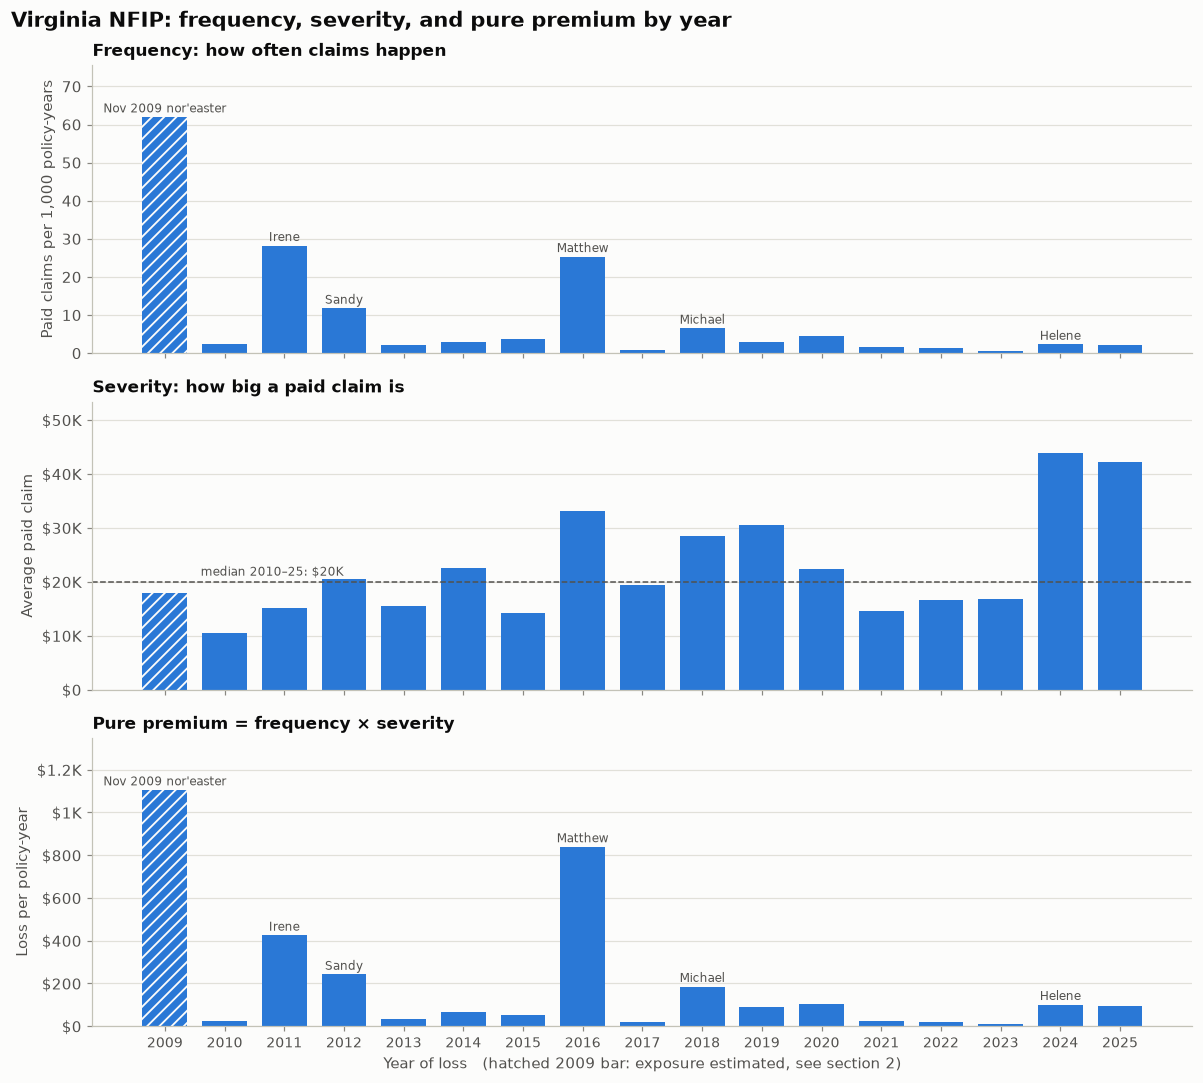

In [8]:
fig, axes = plt.subplots(3, 1, figsize=(11, 10), sharex=True)
panels = [("frequency", 1000, "Paid claims per 1,000 policy-years", "Frequency: how often claims happen", None),
          ("severity", 1, "Average paid claim", "Severity: how big a paid claim is", dollars_short),
          ("pure_premium", 1, "Loss per policy-year", "Pure premium = frequency × severity", dollars_short)]
years = by_year.index.to_numpy()
for ax, (col, scale, ylabel, title, fmt) in zip(axes, panels):
    vals = by_year[col].to_numpy() * scale
    bars = ax.bar(years, vals, color=BLUE, width=0.75)
    bars[0].set_hatch("///")              # 2009: exposure is an estimate
    ax.set_title(title, fontsize=11)
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, np.nanmax(vals) * 1.22)
    if fmt:
        ax.yaxis.set_major_formatter(mticker.FuncFormatter(fmt))
    ax.grid(axis="x", visible=False)
    if col != "severity":                 # storms are frequency events; label them where they spike
        for yr, label in STORMS.items():
            ax.annotate(label, (yr, by_year.loc[yr, col] * scale), xytext=(0, 3),
                        textcoords="offset points", ha="center", fontsize=8, color=INK_2)
    else:
        med = np.nanmedian(vals[1:])
        ax.axhline(med, color=INK_2, lw=1, ls="--")
        ax.annotate(f"median 2010–25: {dollars_short(med)}", (2009.6, med), xytext=(0, 4),
                    textcoords="offset points", fontsize=8, color=INK_2)
axes[-1].set_xticks(years, [str(y) for y in years], rotation=0, fontsize=9)
axes[-1].set_xlabel("Year of loss   (hatched 2009 bar: exposure estimated, see section 2)")
fig.suptitle("Virginia NFIP: frequency, severity, and pure premium by year", x=0.01, ha="left",
             fontsize=14, fontweight="bold", color=INK)
fig.tight_layout()
save(fig, "measures_by_year")
plt.show()

**Reading the chart.**
* **Frequency is what explodes in storm years.** A storm floods thousands of homes at once, so the *number* of claims jumps 10× or more over a quiet year.
* **Severity moves much less.** In most years a paid claim averages somewhere between \$10K and \$45K. Big storm years aren't always the most severe ones: the 2009 nor'easter had many claims but a lower average claim. Recent years (2024–25) show higher severity, partly because these are nominal dollars (no inflation adjustment) and building costs have risen.
* **Pure premium follows frequency.** Because frequency swings much more than severity, the year-to-year shape of the loss cost is mostly the shape of the claim count.

## 5. Concentration: how much of the losses came from the worst few years?

**Catastrophe-driven** losses means most of the money is lost in a handful of rare, extreme years, not spread evenly. That matters for pricing. The average year includes the bad years, but in a *typical* (median) year the insurer pays far less than the average. So the premium has to build up a reserve in quiet years to pay for the storm years.

Losses (dollars paid) don't depend on exposure, so 2009 is included here with no estimate needed.

In [9]:
losses = by_year.losses.sort_values(ascending=False)          # 2009-2025, worst year first
share = losses / losses.sum()
cum = share.cumsum()
conc = pd.DataFrame({"losses": losses, "share": share, "cumulative share": cum})
display(conc.style.format({"losses": "${:,.0f}", "share": "{:.1%}", "cumulative share": "{:.1%}"}))
n_years = len(losses)
print(f"Worst year ({losses.index[0]}):   {share.iloc[0]:.0%} of all 2009-2025 losses")
print(f"Worst 3 years: {cum.iloc[2]:.0%}   Worst 5 years: {cum.iloc[4]:.0%}   (out of {n_years} years)")
print(f"Mean year: ${losses.mean():,.0f}   Median year: ${losses.median():,.0f}   "
      f"(mean / median = {losses.mean() / losses.median():.1f}x)")
l10 = by_year.loc[YEARS, "losses"].sort_values(ascending=False)
print(f"2010-2025 only: worst 3 of 16 years = {l10.head(3).sum() / l10.sum():.0%} of losses")

,losses,share,cumulative share
year,,,
2009,"$106,098,773",32.5%,32.5%
2016,"$77,620,594",23.8%,56.3%
2011,"$42,108,776",12.9%,69.2%
2012,"$24,629,525",7.5%,76.8%
2018,"$17,471,309",5.4%,82.1%
2020,"$9,617,978",2.9%,85.1%
2019,"$8,593,568",2.6%,87.7%
2024,"$8,100,947",2.5%,90.2%
2025,"$7,376,732",2.3%,92.4%


Worst year (2009):   33% of all 2009-2025 losses
Worst 3 years: 69%   Worst 5 years: 82%   (out of 17 years)
Mean year: $19,193,064   Median year: $7,376,732   (mean / median = 2.6x)
2010-2025 only: worst 3 of 16 years = 66% of losses


saved reports\figures\02_loss_concentration.png


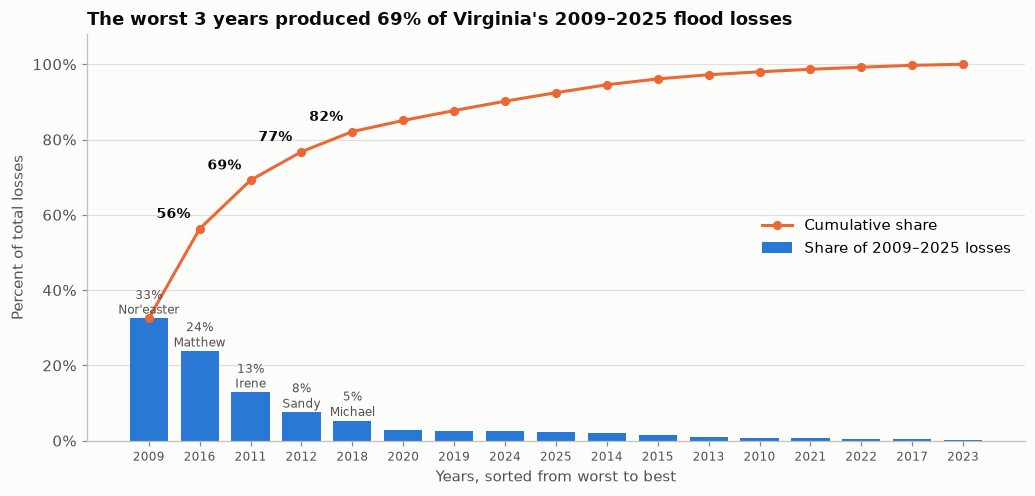

In [10]:
fig, ax = plt.subplots(figsize=(11, 4.8))
pos = np.arange(n_years)
ax.bar(pos, share * 100, color=BLUE, width=0.75, label="Share of 2009–2025 losses")
ax.plot(pos, cum * 100, color=ORANGE, lw=2, marker="o", ms=5, label="Cumulative share")
for i in range(1, 5):   # cumulative share after the worst 2, 3, 4, 5 years
    ax.annotate(f"{cum.iloc[i]:.0%}", (pos[i], cum.iloc[i] * 100), xytext=(-6, 7),
                textcoords="offset points", ha="right", fontsize=9, color=INK, fontweight="bold")
short = {2009: "Nor'easter"}
for i, yr in enumerate(losses.index[:5]):
    ax.annotate(f"{share.iloc[i]:.0%}\n{short.get(yr, STORMS.get(yr, ''))}", (pos[i], share.iloc[i] * 100),
                xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8, color=INK_2)
ax.set_xticks(pos, [str(y) for y in losses.index], fontsize=8)
ax.set_ylim(0, 108)
ax.yaxis.set_major_formatter(mticker.PercentFormatter())
ax.set_ylabel("Percent of total losses")
ax.set_xlabel("Years, sorted from worst to best")
ax.set_title(f"The worst 3 years produced {cum.iloc[2]:.0%} of Virginia's 2009–2025 flood losses")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, loc="center right")
save(fig, "loss_concentration")
plt.show()

## 6. By county

Claims use the claim's `countyCode`. Policies use the first 5 digits of `censusGeoid`. In Virginia, **independent cities** (Virginia Beach, Norfolk, …) are county-level areas with their own codes, so they appear in this list too.

**Credibility floor.** A county with only 300 policy-years can post a huge pure premium from a single big claim: that's luck, not risk. Actuaries call this **credibility**: how much you can trust a number given how much data stands behind it. Here we only rank counties with at least **5,000 policy-years** over 2010–2025 (about 300 policies a year). It's a simple rule of thumb; the models will handle this more formally later.

In [11]:
exp_cty = act.earned_exposure(pol, YEARS, by=["county"])
cty_year = act.summarize(exp_cty, act.claim_totals(clm, by=["county"]), by=["county"])

# Reconciliation: claims in counties we can't match to exposure
matched = int(cty_year.dropna(subset=["county"]).claims_all.sum())
total = int(clm.yearOfLoss.between(2010, 2025).sum())
assert int(cty_year.claims_all.sum()) == total     # no claim lost in the join
print(f"2010-2025 claims with a known county, matched to exposure: {matched:,} of {total:,} ({matched / total:.2%})")
print(f"Policy-years with unknown county: {exp_cty[exp_cty.county.isna()].exposure.sum():,.0f} "
      f"({exp_cty[exp_cty.county.isna()].exposure.sum() / exp_cty.exposure.sum():.2%})")

cty = act.collapse(cty_year.dropna(subset=["county"]), ["county"])
cty["name"] = cty.county.map(names).fillna("FIPS " + cty.county)
cty["share_of_losses"] = cty.losses / cty.losses.sum()
cty["share_of_exposure"] = cty.exposure / cty.exposure.sum()
MIN_EXPOSURE = 5_000
credible = cty[cty.exposure >= MIN_EXPOSURE]
print(f"{len(cty)} counties/cities with exposure; {len(credible)} pass the {MIN_EXPOSURE:,} policy-year floor "
      f"and hold {credible.exposure.sum() / cty.exposure.sum():.0%} of exposure")

top15 = credible.sort_values("pure_premium", ascending=False).head(15).reset_index(drop=True)
top15.index += 1
table = top15[["name", "county", "exposure", "claims", "frequency", "severity", "pure_premium",
               "share_of_losses", "share_of_exposure"]].copy()
table["frequency"] *= 1000
table = table.rename(columns={"frequency": "freq per 1,000"})
display(table.style.format({"exposure": "{:,.0f}", "claims": "{:,.0f}", "freq per 1,000": "{:.2f}",
                            "severity": "${:,.0f}", "pure_premium": "${:,.0f}",
                            "share_of_losses": "{:.1%}", "share_of_exposure": "{:.1%}"}))
state_pp = full.pure_premium[0]
print(f"Statewide pure premium 2010-2025: ${state_pp:,.0f}. "
      f"Top 15 hold {top15.share_of_exposure.sum():.0%} of exposure and {top15.share_of_losses.sum():.0%} of losses.")

2010-2025 claims with a known county, matched to exposure: 12,535 of 12,545 (99.92%)
Policy-years with unknown county: 6,732 (0.45%)
141 counties/cities with exposure; 32 pass the 5,000 policy-year floor and hold 90% of exposure


,name,county,exposure,claims,"freq per 1,000",severity,pure_premium,share_of_losses,share_of_exposure
1,Salem city,51775,"6,485",83,12.80,"$35,521",$455,1.3%,0.4%
2,Newport News city,51700,"34,288",339,9.89,"$43,532",$430,6.7%,2.3%
3,Roanoke County,51161,"6,711",101,15.05,"$20,247",$305,0.9%,0.5%
4,Roanoke city,51770,"8,619",125,14.50,"$20,744",$301,1.2%,0.6%
5,Alexandria city,51510,"18,415",171,9.29,"$24,674",$229,1.9%,1.2%
6,Virginia Beach city,51810,"298,421","2,072",6.94,"$31,961",$222,30.1%,20.2%
7,Suffolk city,51800,"15,328",78,5.09,"$39,028",$199,1.4%,1.0%
8,Portsmouth city,51740,"55,140",425,7.71,"$20,587",$159,4.0%,3.7%
9,Arlington County,51013,"10,819",83,7.67,"$20,031",$154,0.8%,0.7%
10,Norfolk city,51710,"154,653","1,333",8.62,"$16,083",$139,9.7%,10.5%


Statewide pure premium 2010-2025: $149. Top 15 hold 54% of exposure and 68% of losses.


saved reports\figures\02_top_counties_pure_premium.png


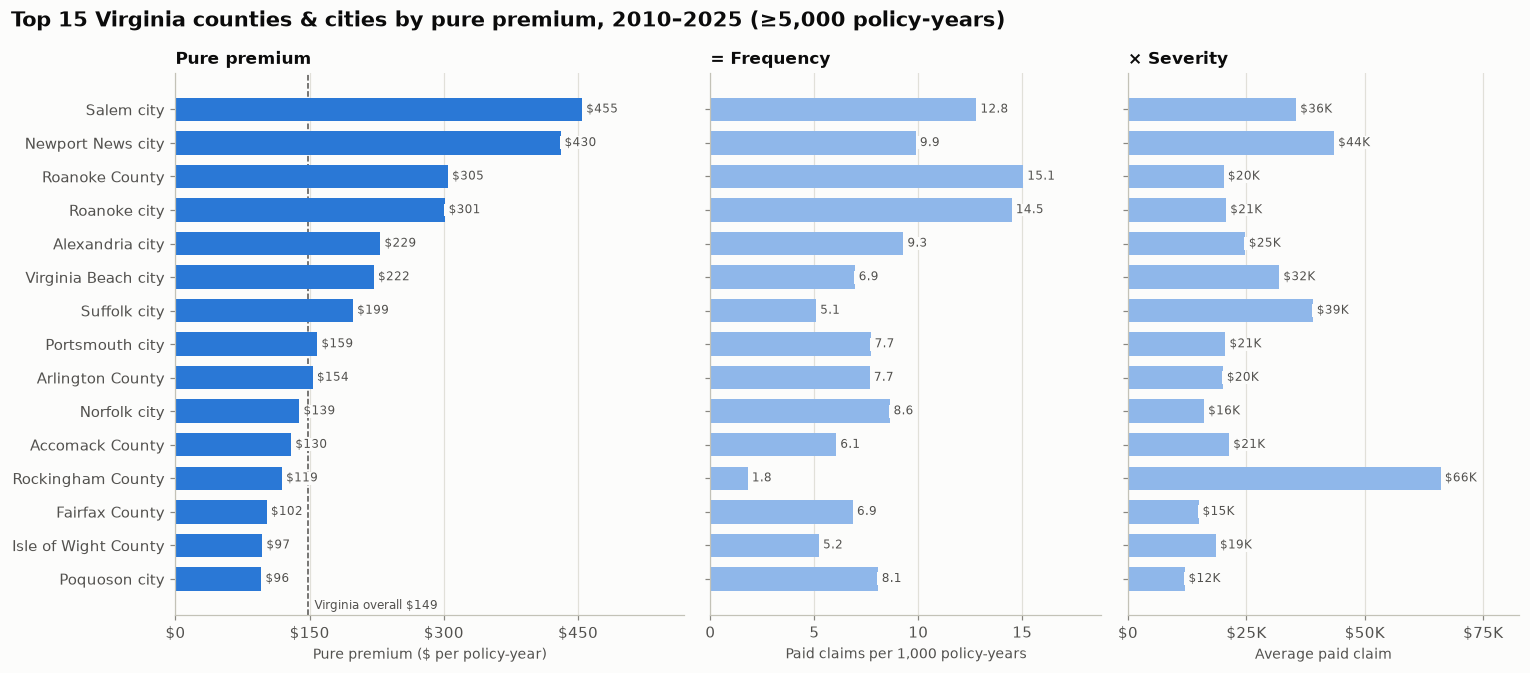

In [12]:
t = top15.iloc[::-1]
labels = [f"{n}" for n in t.name]
fig, axes = plt.subplots(1, 3, figsize=(14, 6.2), sharey=True,
                         gridspec_kw={"width_ratios": [1.3, 1, 1]})
specs = [("pure_premium", 1, "Pure premium ($ per policy-year)", dollars_short, fmt_money),
         ("frequency", 1000, "Paid claims per 1,000 policy-years", None, lambda v: f"{v:.1f}"),
         ("severity", 1, "Average paid claim", dollars_short, dollars_short)]
for ax, (col, scale, xlabel, axfmt, lblfmt) in zip(axes, specs):
    vals = t[col] * scale
    ax.barh(labels, vals, color=BLUE if col == "pure_premium" else "#8fb7ea", height=0.7)
    ax.set_xlabel(xlabel, fontsize=9)
    ax.set_xlim(0, vals.max() * 1.25)
    ax.xaxis.set_major_locator(mticker.MaxNLocator(4))
    if axfmt:
        ax.xaxis.set_major_formatter(mticker.FuncFormatter(axfmt))
    ax.grid(axis="y", visible=False)
    for y, v in enumerate(vals):
        ax.text(v, y, " " + lblfmt(v), va="center", fontsize=8, color=INK_2,
                bbox=dict(facecolor=SURFACE, edgecolor="none", pad=0.2))
axes[0].axvline(state_pp, color=INK_2, lw=1, ls="--", zorder=0.5)
axes[0].annotate(f"Virginia overall {fmt_money(state_pp)}", (state_pp, -0.9), xytext=(4, 0),
                 textcoords="offset points", fontsize=8, color=INK_2, annotation_clip=False)
axes[0].set_title("Pure premium", fontsize=11)
axes[1].set_title("= Frequency", fontsize=11)
axes[2].set_title("× Severity", fontsize=11)
fig.suptitle(f"Top 15 Virginia counties & cities by pure premium, 2010–2025 (≥{MIN_EXPOSURE:,} policy-years)",
             x=0.01, ha="left", fontsize=14, fontweight="bold", color=INK)
fig.tight_layout()
save(fig, "top_counties_pure_premium")
plt.show()

In [13]:
# For contrast: where are the most total dollars? (big policy bases, not necessarily the highest rate)
by_dollars = cty.sort_values("losses", ascending=False).head(8)
display(by_dollars[["name", "exposure", "losses", "share_of_losses", "share_of_exposure", "pure_premium"]]
        .style.format({"exposure": "{:,.0f}", "losses": "${:,.0f}", "share_of_losses": "{:.1%}",
                       "share_of_exposure": "{:.1%}", "pure_premium": "${:,.0f}"}))

,name,exposure,losses,share_of_losses,share_of_exposure,pure_premium
135,Virginia Beach city,"298,421","$66,223,449",30.1%,20.2%,$222
124,Norfolk city,"154,653","$21,438,596",9.7%,10.5%,$139
123,Newport News city,"34,288","$14,757,333",6.7%,2.3%,$430
115,Hampton city,"158,300","$12,355,162",5.6%,10.7%,$78
106,Chesapeake city,"131,134","$8,873,322",4.0%,8.9%,$68
128,Portsmouth city,"55,140","$8,749,366",4.0%,3.7%,$159
34,Fairfax County,"75,514","$7,719,157",3.5%,5.1%,$102
6,Accomack County,"54,155","$7,013,897",3.2%,3.7%,$130


## 7. What do frequency and severity look like as distributions?

Models need an assumption about the *shape* of the randomness. The classic starting points are:

* **Poisson for claim counts.** A **Poisson distribution** describes counts of rare events that happen independently, like the number of claims among many policies, each with a small chance of a claim. It has one parameter, the average, and its variance equals its mean. That's easy to fit and interpret, and with exposure as an "offset" it naturally models "claims per policy-year."
* **Gamma for claim sizes.** A **Gamma distribution** only allows positive values and has a long right tail (a few very big values). That matches claim payments, where most claims are moderate and a few are huge. In a Gamma model the spread grows with the mean, which fits money amounts well: claims on bigger houses vary more in dollars.

Below we check both against the data. Frequency uses **county-years** (one county in one year, 2010–2025). Because counties differ in size, the Poisson comparison gives each county-year its own expected count, λ = its exposure × the statewide frequency.

In [14]:
cy = cty_year.dropna(subset=["county"])
cy = cy[cy.exposure > 0].copy()
cy["expected"] = cy.exposure * full.frequency[0]          # Poisson mean if every county had the state rate
n = cy.claims.to_numpy()

# Overdispersion check. For a Poisson, (count - expected)^2 / expected averages to about 1.
pearson = ((n - cy.expected) ** 2 / cy.expected).sum() / (len(cy) - 1)
print(f"County-years: {len(cy):,}. Mean paid claims {n.mean():.2f}, variance {n.var():,.0f}, "
      f"variance / mean = {n.var() / n.mean():,.0f}")
print(f"Exposure-adjusted dispersion (should be ~1 for Poisson): {pearson:,.0f}")
print(f"County-years with zero paid claims: observed {(n == 0).mean():.0%}, "
      f"Poisson predicts {np.exp(-cy.expected).mean():.0%}")

# Severity: fit a Gamma to individual paid claims (2009-2025, nominal $)
paid = clm.loc[clm.is_paid & clm.yearOfLoss.between(2009, 2025), "total_paid"].to_numpy()
shape, loc, scale_g = stats.gamma.fit(paid, floc=0)
gam = stats.gamma(shape, loc=0, scale=scale_g)
print(f"\nPaid claims: {len(paid):,}. Mean ${paid.mean():,.0f}, median ${np.median(paid):,.0f}")
print(f"Fitted Gamma: shape {shape:.2f}, mean ${gam.mean():,.0f}")
for q in [0.5, 0.9, 0.99]:
    print(f"  {q:.0%} quantile: data ${np.quantile(paid, q):>10,.0f}   Gamma ${gam.ppf(q):>10,.0f}")

County-years: 2,181. Mean paid claims 4.38, variance 1,451, variance / mean = 331
Exposure-adjusted dispersion (should be ~1 for Poisson): 28
County-years with zero paid claims: observed 66%, Poisson predicts 49%

Paid claims: 15,506. Mean $21,042, median $10,172
Fitted Gamma: shape 0.79, mean $21,042
  50% quantile: data $    10,172   Gamma $    13,120
  90% quantile: data $    51,389   Gamma $    51,288
  99% quantile: data $   154,992   Gamma $   109,188


saved reports\figures\02_distributions.png


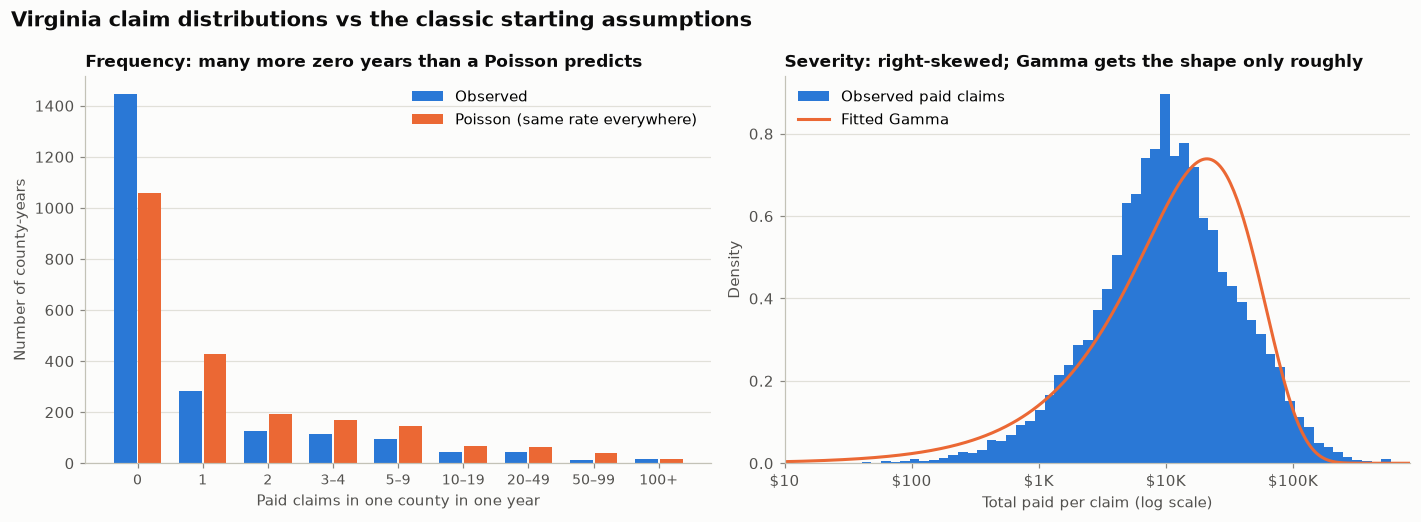

In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))

# Left: claim counts per county-year, observed vs exposure-adjusted Poisson
edges = [0, 1, 2, 3, 5, 10, 20, 50, 100, 10_000]
labels_c = ["0", "1", "2", "3–4", "5–9", "10–19", "20–49", "50–99", "100+"]
obs = pd.cut(n, edges, right=False, labels=labels_c).value_counts().reindex(labels_c)
lam = cy.expected.to_numpy()
cdf = lambda k: stats.poisson.cdf(k - 1, lam).sum()       # expected number of county-years with count < k
expct = np.diff([cdf(e) for e in edges])
xx = np.arange(len(labels_c))
w = 0.38
ax1.bar(xx - w / 2, obs.values, width=w - 0.03, color=BLUE, label="Observed")
ax1.bar(xx + w / 2, expct, width=w - 0.03, color=ORANGE, label="Poisson (same rate everywhere)")
ax1.set_xticks(xx, labels_c, fontsize=9)
ax1.set_xlabel("Paid claims in one county in one year")
ax1.set_ylabel("Number of county-years")
ax1.set_title("Frequency: many more zero years than a Poisson predicts", fontsize=11)
ax1.grid(axis="x", visible=False)
ax1.legend(frameon=False)

# Right: severity on a log axis, with the fitted Gamma curve
logbins = np.linspace(np.log10(paid.min()), np.log10(paid.max()) + 0.01, 70)
ax2.hist(np.log10(paid), bins=logbins, density=True, color=BLUE, label="Observed paid claims")
u = np.linspace(logbins[0], logbins[-1], 400)
ax2.plot(u, gam.pdf(10 ** u) * 10 ** u * np.log(10), color=ORANGE, lw=2, label="Fitted Gamma")
ax2.xaxis.set_major_locator(mticker.FixedLocator(range(0, 8)))
ax2.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, p: dollars_short(10 ** v)))
ax2.set_xlim(1, logbins[-1])
ax2.set_xlabel("Total paid per claim (log scale)")
ax2.set_ylabel("Density")
ax2.set_title("Severity: right-skewed; Gamma gets the shape only roughly", fontsize=11)
ax2.grid(axis="x", visible=False)
ax2.legend(frameon=False, loc="upper left")
fig.suptitle("Virginia claim distributions vs the classic starting assumptions", x=0.01, ha="left",
             fontsize=14, fontweight="bold", color=INK)
fig.tight_layout()
save(fig, "distributions")
plt.show()

**What this tells us for modelling.**
* **Frequency is badly overdispersed.** **Overdispersion** means the counts vary much more than a Poisson allows (for a Poisson, variance = mean). Part of that is real differences between counties (coastal vs inland), which the model's predictors (flood zone, location, …) are meant to explain. A big part is that storms make claims happen *together*, so they aren't independent. The usual fix is the **negative binomial** distribution: like a Poisson, but with an extra parameter that lets the variance exceed the mean. Poisson remains the natural *first* model: it's simple, and its average predictions are still unbiased even when the variance is off.
* **Severity is right-skewed, and a Gamma is a reasonable first pass.** Gamma gets the general shape (positive values, a long right tail) but not every detail; the quantile comparison above shows where it misses. The fitted shape is below 1, so it puts too much weight on tiny claims, and it under-states the biggest ones (its 99th percentile is about \$109K vs about \$155K in the data). Heavier-tailed choices (like the **lognormal**) or capping very large claims are common refinements.
* **Catastrophes are the elephant in the room.** No simple distribution captures "most years are quiet, a few years are enormous." Pricing usually handles that separately, with a catastrophe load or by holding out storm years when testing models.

In [16]:
# Save the county-year table (2009-2025, 2009 exposure estimated) for the modelling notebooks.
# It goes to data/processed/, which is never committed to Git.
tbl = act.build_county_year(save=True)
print(f"saved data/processed/va_county_year.parquet: {len(tbl):,} rows, columns: {list(tbl.columns)}")

saved data/processed/va_county_year.parquet: 2,409 rows, columns: ['county', 'year', 'exposure', 'exposure_is_estimate', 'claims_all', 'claims', 'losses', 'frequency', 'frequency_all', 'severity', 'pure_premium']


## Takeaways
The interview-ready findings are written up in `reports/02_actuarial_basics.md`. Next step (week 2): clean the data, adjust dollars for inflation, and build the county-year modelling table with predictors (flood zone mix, coastal vs inland, building characteristics).